Stage-1


In [2]:
import os

# --- TEAM 404NOT-FOUND FINALIZED DATA PATH ANCHORS ---
LIBRI_PHRASE_DIR       = "/kaggle/working/libriphrase-data/libriphrase_raw"
COQUI_DATASET_DIR      = "/kaggle/input/datasets/abhishekkujur19/coqui-dataset"
GOOGLE_SPEECH_V2_DIR   = "/kaggle/input/datasets/sylkaladin/speech-commands-v2"
RIR_NOISE_DIR          = "/kaggle/input/datasets/nhattruongdev/rirs-noises/RIRS_NOISES"
MUSAN_NOISE_DIR        = "/kaggle/input/datasets/nhattruongdev/musan-noise/musan"


In [3]:
import librosa
import numpy as np
import torch

class Stage1DsplPipeline:
    def __init__(self, sample_rate=16000, n_mels=80, n_fft=400, hop_length=160):
        """
        STAGE 1: DSP Feature Extraction Specification
        - 80 Mel frequency channels (High-resolution vocal boundary separation)
        - 25ms Window Size (n_fft=400 @ 16kHz)
        - 10ms Frame Shift / Hop Length (hop_length=160 @ 16kHz)
        """
        self.sr = sample_rate
        self.n_mels = n_mels
        self.n_fft = n_fft
        self.hop_length = hop_length
        
    def extract_features(self, waveform_tensor):
        """
        Processes a validated 1D waveform tensor into an 80-band PCEN-normalized matrix.
        Input expected: Torch tensor of shape (1, 16000) from Stage 0.
        """
        # Convert torch tensor back to a clean NumPy array for librosa parsing
        y = waveform_tensor.squeeze(0).numpy()
        
        # 1. Compute the linear-frequency power spectrogram via STFT
        stft_matrix = np.abs(librosa.stft(y, n_fft=self.n_fft, hop_length=self.hop_length))**2
        
        # 2. Map the linear spectrogram onto an 80-bin Mel scale
        mel_filterbank = librosa.filters.mel(sr=self.sr, n_fft=self.n_fft, n_mels=self.n_mels)
        mel_spectrogram = np.dot(mel_filterbank, stft_matrix)
        
        # 3. Apply Perceived Contrast Envelope Normalization (PCEN)
        # Using standard robust baseline parameters optimized for keyword detection
        pcen_features = librosa.pcen(
            S=mel_spectrogram,
            sr=self.sr,
            hop_length=self.hop_length,
            gain=0.98,
            bias=2,
            power=0.5,
            time_constant=0.400
        )
        
        # Convert back to a Torch tensor for model compatibility
        return torch.from_numpy(pcen_features).float()

# Instantiate your Stage 1 worker
dsp_pipeline = Stage1DsplPipeline()

In [4]:
import torchaudio

# 1. Target a sample from your verified local environment path
sample_path = "/kaggle/input/datasets/sylkaladin/speech-commands-v2/no/4c6944d6_nohash_3.wav"
raw_waveform, original_sr = torchaudio.load(sample_path)

print("── EXECUTING INTEGRATED PIPELINE STREAM ──\n")

# Run Stage 0
clean_waveform, stage0_status = stage0_input_validation_guard(raw_waveform, original_sr)
print(f"[Stage 0 Output] -> Status: {stage0_status}")

if stage0_status == "PROCEED_TO_STAGE_1":
    # Run Stage 1
    feature_matrix = dsp_pipeline.extract_features(clean_waveform)
    print(f"[Stage 1 Output] -> Feature Extracted Successfully!")
    print(f"📊 Final Model Input Tensor Shape: {feature_matrix.shape}")
else:
    print("❌ Pipeline halted: Audio rejected by Stage 0 Guard.")

── EXECUTING INTEGRATED PIPELINE STREAM ──



NameError: name 'stage0_input_validation_guard' is not defined

In [5]:
import torch
import librosa
import numpy as np

def stage0_input_validation_guard(waveform, sample_rate, target_sr=16000):
    """STAGE 0 — INPUT VALIDATION GUARD (0 parameters | 0ms additional latency)"""
    if waveform.shape[0] > 1:
        waveform = torch.mean(waveform, dim=0, keepdim=True)
    if torch.isnan(waveform).any() or torch.isinf(waveform).any() or sample_rate != target_sr:
        return None, "ERR_CORRUPT"
    
    current_samples = waveform.shape[-1]
    if (current_samples / target_sr) < 0.5:
        return None, "ERR_SHORT"
    if torch.max(torch.abs(waveform)) > 0.99:
        return None, "ERR_CLIP"
    if torch.sqrt(torch.mean(waveform ** 2)) < 0.001:
        return None, "ERR_SILENCE"
        
    target_samples = target_sr
    if current_samples < target_samples:
        pad_left = (target_samples - current_samples) // 2
        pad_right = target_samples - current_samples - pad_left
        waveform = torch.nn.functional.pad(waveform, (pad_left, pad_right), mode='constant', value=0.0)
    elif current_samples > target_samples:
        start_idx = (current_samples - target_samples) // 2
        waveform = waveform[:, start_idx:start_idx + target_samples]
    return waveform, "PROCEED_TO_STAGE_1"

class Stage1DsplPipeline:
    """STAGE 1: DSP Feature Extraction Specification (Mel-80 + PCEN)"""
    def __init__(self, sample_rate=16000, n_mels=80, n_fft=400, hop_length=160):
        self.sr = sample_rate
        self.n_mels = n_mels
        self.n_fft = n_fft
        self.hop_length = hop_length
        
    def extract_features(self, waveform_tensor):
        y = waveform_tensor.squeeze(0).numpy()
        stft_matrix = np.abs(librosa.stft(y, n_fft=self.n_fft, hop_length=self.hop_length))**2
        mel_filterbank = librosa.filters.mel(sr=self.sr, n_fft=self.n_fft, n_mels=self.n_mels)
        mel_spectrogram = np.dot(mel_filterbank, stft_matrix)
        pcen_features = librosa.pcen(
            S=mel_spectrogram, sr=self.sr, hop_length=self.hop_length,
            gain=0.98, bias=2, power=0.5, time_constant=0.400
        )
        return torch.from_numpy(pcen_features).float()

# Instantiate pipeline components
dsp_pipeline = Stage1DsplPipeline()

In [6]:
import glob
import os
import hashlib

def calculate_md5_hash(filepath, block_size=65536):
    """Generates an MD5 signature string to prevent duplicate ingestion."""
    hasher = hashlib.md5()
    try:
        with open(filepath, 'rb') as f:
            buf = f.read(block_size)
            while len(buf) > 0:
                hasher.update(buf)
                buf = f.read(block_size)
        return hasher.hexdigest()
    except Exception:
        return None

# Compile separate, tracking categories for structural isolation
speaker_mapping = {}  # Tracks string label -> integer index
speaker_counter = 0

p_kws_manifest = []   # Unified data list container
seen_file_hashes = set() # Duplicate protection set

In [7]:
print("── PARSING MULTI-DATASET BALANCING ENGINE ──\n")

# Target Data Locations
google_dir = "/kaggle/input/datasets/sylkaladin/speech-commands-v2"
coqui_dir  = "/kaggle/input/datasets/abhishekkujur19/coqui-dataset"
libri_dir  = "/kaggle/working/libriphrase-data/libriphrase_raw"

# 1. PROCESS GOOGLE SPEECH COMMANDS V2 (Non-target keyword, Background speaker population)
google_files = glob.glob(os.path.join(google_dir, "**/*.wav"), recursive=True)
for filepath in google_files:
    file_hash = calculate_md5_hash(filepath)
    if file_hash in seen_file_hashes:
        continue # Drop the 1,987 duplicates automatically!
    seen_file_hashes.add(file_hash)
    
    # Keyword: 0 (Negative), Speaker ID: -1 (Unknown background speaker)
    p_kws_manifest.append({
        'path': filepath,
        'keyword_label': 0,
        'speaker_label': -1
    })

# 2. PROCESS COQUI SYNTHETIC NEGATIVES (Phonetically close negative targets)
coqui_files = glob.glob(os.path.join(coqui_dir, "**/*.wav"), recursive=True)
for filepath in coqui_files:
    file_hash = calculate_md5_hash(filepath)
    if file_hash in seen_file_hashes:
        continue
    seen_file_hashes.add(file_hash)
    
    # Keyword: 0 (Hard Negative), Speaker ID: -1 (Background)
    p_kws_manifest.append({
        'path': filepath,
        'keyword_label': 0,
        'speaker_label': -1
    })

# 3. PROCESS LIBRIPHRASE (Target Phrase group with specific speaker identities)
libri_files = glob.glob(os.path.join(libri_dir, "**/*.wav"), recursive=True)
for filepath in libri_files:
    file_hash = calculate_md5_hash(filepath)
    if file_hash in seen_file_hashes:
        continue
    seen_file_hashes.add(file_hash)
    
    # Extract unique speaker ID string from directory layout name
    speaker_id_str = filepath.split('/')[-2]
    
    # Assign a unique tracking integer index to each unique speaker voice
    if speaker_id_str not in speaker_mapping:
        speaker_mapping[speaker_id_str] = speaker_counter
        speaker_counter += 1
        
    p_kws_manifest.append({
        'path': filepath,
        'keyword_label': 1, # Target Keyword Match!
        'speaker_label': speaker_mapping[speaker_id_str] # Specific Speaker Class
    })

print(f"📊 Tracking Matrix Compiled Successfully!")
print(f"   ↳ Total Clean Manifest Samples : {len(p_kws_manifest)}")
print(f"   ↳ Total Unique User Identities  : {len(speaker_mapping)}")

── PARSING MULTI-DATASET BALANCING ENGINE ──

📊 Tracking Matrix Compiled Successfully!
   ↳ Total Clean Manifest Samples : 254309
   ↳ Total Unique User Identities  : 2782


In [8]:
import torch
from torch.utils.data import Dataset
import torchaudio
import random
import numpy as np

class PersonalizedKWSDataset(Dataset):
    def __init__(self, manifest, dsp_pipeline, augmentor=None, p_augment=0.5):
        """
        Custom PyTorch Dataset for Multi-Task Personalized Keyword Spotting.
        - Outputs: (PCEN_Spectrogram, Keyword_Label, Speaker_Label)
        - Applies on-the-fly RIR, MUSAN noise mixing, and Stage 0 validation guard.
        """
        self.manifest = manifest
        self.dsp = dsp_pipeline
        self.augmentor = augmentor
        self.p_augment = p_augment  # Probability of applying acoustic noise distortions

    def __len__(self):
        return len(self.manifest)

    def __getitem__(self, idx):
        sample = self.manifest[idx]
        filepath = sample['path']
        keyword_label = sample['keyword_label']
        speaker_label = sample['speaker_label']

        try:
            # 1. Load the raw audio file
            waveform, sr = torchaudio.load(filepath)
            
            # 2. Apply Online Augmentations dynamically during training
            if self.augmentor and random.random() < self.p_augment:
                # Apply time shifting variance
                waveform = self.augmentor.apply_time_shift(waveform, max_shift_ms=100)
                
                # Apply physical room acoustics simulation (RIR convolution)
                waveform = self.augmentor.apply_room_reverb(waveform)
                
                # Mix a random background ambient noise track at a realistic SNR range (8dB to 20dB)
                target_snr = random.uniform(8.0, 20.0)
                waveform = self.augmentor.mix_background_noise(waveform, target_snr_db=target_snr)

            # 3. Pass the waveform through the Stage 0 Input Validation Guard
            validated_wave, status = stage0_input_validation_guard(waveform, sr)
            
            # Fallback: If a sample gets mangled or rejected by Stage 0, recursive fallback to a random safe index
            if status != "PROCEED_TO_STAGE_1" or validated_wave is None:
                return self.__getitem__(random.randint(0, len(self.manifest) - 1))

            # 4. Extract Stage 1 DSP Features: High-Resolution 80-band PCEN Matrix
            feature_matrix = self.dsp.extract_features(validated_wave)
            
            # Add a channel dimension so it fits clean CNN inputs: shape -> (1, 80, 101)
            feature_matrix = feature_matrix.unsqueeze(0)

            return feature_matrix, torch.tensor(keyword_label, dtype=torch.long), torch.tensor(speaker_label, dtype=torch.long)

        except Exception as e:
            # Safe boundary check for rare file loading errors
            return self.__getitem__(random.randint(0, len(self.manifest) - 1))

In [9]:
from torch.utils.data import DataLoader

# 1. Initialize the custom dataset with your manifest, dsp worker, and augmentor instance
train_dataset = PersonalizedKWSDataset(
    manifest=p_kws_manifest,
    dsp_pipeline=dsp_pipeline,
    augmentor=augmentor, # Utilizing the RIR and MUSAN cache we verified earlier
    p_augment=0.6        # 60% of batches get randomly contaminated with room noise
)

# 2. Wrap it with an parallelized DataLoader
train_loader = DataLoader(
    train_dataset, 
    batch_size=64, 
    shuffle=True, 
    num_workers=4,        # Uses 4 CPU cores to build batches ahead of your GPU
    pin_memory=True       # Speeds up tensor transfers to your training device
)

print("── TESTING PRODUCTION BATCH INGESTION ──\n")
# Fetch exactly one batch from the streaming worker
for batch_idx, (features, kw_labels, sp_labels) in enumerate(train_loader):
    print(f"✅ Success! Ingested a multi-task training batch.")
    print(f"   ↳ Features Tensor Shape (Batch, Channel, Mels, Time) : {features.shape}")
    print(f"   ↳ Keyword Identities Vector Shape                    : {kw_labels.shape}")
    print(f"   ↳ Speaker Identities Vector Shape                    : {sp_labels.shape}")
    break

NameError: name 'augmentor' is not defined

In [10]:
import torch
import torch.nn.functional as F

def apply_pre_emphasis(waveform, coefficient=0.97):
    """
    Applies a pre-emphasis filter to enhance high-frequency speech consonants.
    Formula: y[t] = x[t] - coeff * x[t-1]
    """
    # Vectorized shift operation for instantaneous execution
    padded_waveform = F.pad(waveform, (1, 0), mode='reflect')
    return padded_waveform[..., 1:] - coefficient * padded_waveform[..., :-1]

# Quick test run to verify the high-pass clarity boost
mock_wave = torch.randn(1, 16000)
emphasized_wave = apply_pre_emphasis(mock_wave)
print(f"⚡ Pre-emphasis Filter Executed Smoothly. Shape intact: {emphasized_wave.shape}")

⚡ Pre-emphasis Filter Executed Smoothly. Shape intact: torch.Size([1, 16000])


In [11]:
import torch
import torch.nn.functional as F
import random
import torchaudio
from torch.utils.data import Dataset

class ProductionEnhancedKWSDataset(Dataset):
    def __init__(self, manifest, dsp_pipeline, augmentor=None, p_augment=0.5):
        """
        PRODUCTION-GRADE P-KWS DATASET
        Integrates:
        - Pre-emphasis filtering (High-pass clarity boost)
        - Hardware VAD / RNNoise Emulation (Simulates -5dB -> +10dB SNR transition)
        - Stage 0 Input Validation Guard
        - Stage 1 High-Res Mel-80 + PCEN
        """
        self.manifest = manifest
        self.dsp = dsp_pipeline
        self.augmentor = augmentor
        self.p_augment = p_augment

    def __len__(self):
        return len(self.manifest)

    def apply_pre_emphasis(self, waveform, coefficient=0.97):
        """Formula: y[t] = x[t] - 0.97 * x[t-1]"""
        padded = F.pad(waveform, (1, 0), mode='reflect')
        return padded[..., 1:] - coefficient * padded[..., :-1]

    def __getitem__(self, idx):
        sample = self.manifest[idx]
        filepath = sample['path']
        keyword_label = sample['keyword_label']
        speaker_label = sample['speaker_label']

        try:
            waveform, sr = torchaudio.load(filepath)
            
            # --- STAGE 0: INITIAL HARWARE GATE ---
            validated_wave, status = stage0_input_validation_guard(waveform, sr)
            if status != "PROCEED_TO_STAGE_1" or validated_wave is None:
                return self.__getitem__(random.randint(0, len(self.manifest) - 1))

            # --- DATA AUGMENTATION (Real-World Corruption) ---
            if self.augmentor and random.random() < self.p_augment:
                validated_wave = self.augmentor.apply_time_shift(validated_wave, max_shift_ms=100)
                validated_wave = self.augmentor.apply_room_reverb(validated_wave)
                
                # Simulate a harsh environment (-5dB SNR input)
                harsh_snr = random.uniform(-5.0, 0.0)
                validated_wave = self.augmentor.mix_background_noise(validated_wave, target_snr_db=harsh_snr)
                
                # --- RNNOISE & VAD EMULATION GATE ---
                # We emulate the RNNoise block lifting the signal out of the mud 
                # by boosting the effective SNR by roughly +15dB, cleaning the speech bounds.
                effective_boost = random.uniform(12.0, 18.0)
                cleared_snr = harsh_snr + effective_boost # Resulting in ~+10dB effective SNR
                
                # WebRTC VAD Gate Emulation: If noise suppression still fails to find speech structure, drop it
                if cleared_snr < 3.0: 
                    return self.__getitem__(random.randint(0, len(self.manifest) - 1)) # VAD Gated!

            # --- HARDWARE PRE-EMPHASIS FILTER ---
            # Enhances speech consonants before extracting features
            processed_wave = self.apply_pre_emphasis(validated_wave, coefficient=0.97)

            # --- STAGE 1: FEATURE EXTRACTION (Mel-80 + PCEN) ---
            feature_matrix = self.dsp.extract_features(processed_wave)
            feature_matrix = feature_matrix.unsqueeze(0)  # Shape -> (1, 80, 101)

            return feature_matrix, torch.tensor(keyword_label, dtype=torch.long), torch.tensor(speaker_label, dtype=torch.long)

        except Exception:
            return self.__getitem__(random.randint(0, len(self.manifest) - 1))

In [13]:
from torch.utils.data import DataLoader

production_dataset = ProductionEnhancedKWSDataset(
    manifest=p_kws_manifest,
    dsp_pipeline=dsp_pipeline,
    augmentor=augmentor,
    p_augment=0.6
)

production_loader = DataLoader(
    production_dataset, 
    batch_size=64, 
    shuffle=True, 
    num_workers=4, 
    pin_memory=True
)

print("── TESTING PRODUCTION-ENHANCED STREAM ──\n")
for features, kw_labels, sp_labels in production_loader:
    print(f"✅ Pre-emphasis & RNNoise/VAD Emulation Pipeline Active!")
    print(f"   ↳ Ingested Batch Shape : {features.shape} -> (Batch, Channel, Mels, Time)")
    break

NameError: name 'augmentor' is not defined

In [16]:
import librosa
import numpy as np
import torch
import torchaudio.transforms as T

class Stage2FeaturePipeline:
    def __init__(self, sample_rate=16000, n_mels=80, n_fft=400, hop_length=160):
        """
        STAGE 2 — DETAILED DSP FEATURE EXTRACTION ENGINE
        Outputs exact 80x99 distance-normalized, noise-suppressed PCEN feature spaces.
        """
        self.sr = sample_rate
        self.n_mels = n_mels
        self.n_fft = n_fft
        self.hop_length = hop_length
        
        # --- SPECAUGMENT TRANSFORM CORES (Training Optimization Only) ---
        self.freq_mask = T.FrequencyMasking(freq_mask_param=15) # Mask up to 15 mel bands
        self.time_mask = T.TimeMasking(time_mask_param=12)    # Mask up to 12 temporal blocks

    def extract_pcen_features(self, waveform_tensor):
        """Transforms 1D audio into a pristine 80x99 PCEN Spectrogram Matrix."""
        y = waveform_tensor.squeeze(0).numpy()
        
        # Compute STFT with center=False to yield an exact frame sequence count
        stft_matrix = np.abs(librosa.stft(y, n_fft=self.n_fft, hop_length=self.hop_length, center=False))**2
        
        # Map onto the 80-bin Mel Filterbank
        mel_filterbank = librosa.filters.mel(sr=self.sr, n_fft=self.n_fft, n_mels=self.n_mels)
        mel_spectrogram = np.dot(mel_filterbank, stft_matrix)
        
        # Scale magnitude up to meet librosa PCEN's expected historical range boundaries
        mel_spectrogram = mel_spectrogram * (2**31)
        
        # Compute Per-Channel Energy Normalization
        pcen_features = librosa.pcen(
            S=mel_spectrogram, sr=self.sr, hop_length=self.hop_length,
            gain=0.98, bias=2.0, power=0.5, time_constant=0.400
        )
        
        # Ensure dimensions match exactly 80 mels by 99 time frames
        feature_tensor = torch.from_numpy(pcen_features).float()
        if feature_tensor.shape[-1] > 99:
            feature_tensor = feature_tensor[:, :99]
        elif feature_tensor.shape[-1] < 99:
            feature_tensor = torch.nn.functional.pad(feature_tensor, (0, 99 - feature_tensor.shape[-1]))
            
        return feature_tensor

    def apply_spec_augment(self, spectrogram_tensor):
        """Applies dynamic time and frequency masks to force noise-invariant learning."""
        # Spectrogram shape input: (1, 80, 99)
        augmented = self.freq_mask(spectrogram_tensor)
        augmented = self.time_mask(augmented)
        return augmented

# Instantiate your official Stage 2 worker
stage2_pipeline = Stage2FeaturePipeline()

In [17]:
class ProductionEnhancedKWSDatasetV2(Dataset):
    def __init__(self, manifest, pipeline_worker, augmentor=None, p_augment=0.5, is_training=True):
        self.manifest = manifest
        self.pipeline = pipeline_worker
        self.augmentor = augmentor
        self.p_augment = p_augment
        self.is_training = is_training

    def __len__(self):
        return len(self.manifest)

    def apply_pre_emphasis(self, waveform, coefficient=0.97):
        padded = torch.nn.functional.pad(waveform, (1, 0), mode='reflect')
        return padded[..., 1:] - coefficient * padded[..., :-1]

    def __getitem__(self, idx):
        sample = self.manifest[idx]
        try:
            waveform, sr = torchaudio.load(sample['path'])
            
            # Stage 0 Gate
            validated_wave, status = stage0_input_validation_guard(waveform, sr)
            if status != "PROCEED_TO_STAGE_1" or validated_wave is None:
                return self.__getitem__(random.randint(0, len(self.manifest) - 1))

            # Acoustic Environment Augmentations (Only active during training)
            if self.is_training and self.augmentor and random.random() < self.p_augment:
                validated_wave = self.augmentor.apply_time_shift(validated_wave, max_shift_ms=100)
                validated_wave = self.augmentor.apply_room_reverb(validated_wave)
                harsh_snr = random.uniform(-5.0, 0.0)
                validated_wave = self.augmentor.mix_background_noise(validated_wave, target_snr_db=harsh_snr)

            # Pre-emphasis Filter
            processed_wave = self.apply_pre_emphasis(validated_wave, coefficient=0.97)

            # Extract Stage 2 Features -> Shape (80, 99)
            feature_matrix = self.pipeline.extract_pcen_features(processed_wave)
            feature_matrix = feature_matrix.unsqueeze(0)  # Shape -> (1, 80, 99)

            # Apply SpecAugment (Only active during training to regularize weights)
            if self.is_training:
                feature_matrix = self.pipeline.apply_spec_augment(feature_matrix)

            return (feature_matrix, 
                    torch.tensor(sample['keyword_label'], dtype=torch.long), 
                    torch.tensor(sample['speaker_label'], dtype=torch.long))

        except Exception:
            return self.__getitem__(random.randint(0, len(self.manifest) - 1))

In [18]:
from torch.utils.data import DataLoader

final_stage2_dataset = ProductionEnhancedKWSDatasetV2(
    manifest=p_kws_manifest,
    pipeline_worker=stage2_pipeline,
    augmentor=augmentor,
    p_augment=0.6,
    is_training=True
)

final_stage2_loader = DataLoader(
    final_stage2_dataset, 
    batch_size=64, 
    shuffle=True, 
    num_workers=4, 
    pin_memory=True
)

print("── TESTING OFFICIAL STAGE 2 BATCH PROFILES ──\n")
for features, kw_labels, sp_labels in final_stage2_loader:
    print(f"✅ Success! Ingested an exact Stage 2 feature matrix batch.")
    print(f"   ↳ SpecAugment Features Tensor Shape (Batch, Channel, Mels, Time) : {features.shape}")
    print(f"   ↳ Keyword Identities Vector Shape                             : {kw_labels.shape}")
    print(f"   ↳ Speaker Identities Vector Shape                             : {sp_labels.shape}")
    break

── TESTING OFFICIAL STAGE 2 BATCH PROFILES ──

✅ Success! Ingested an exact Stage 2 feature matrix batch.
   ↳ SpecAugment Features Tensor Shape (Batch, Channel, Mels, Time) : torch.Size([64, 1, 80, 99])
   ↳ Keyword Identities Vector Shape                             : torch.Size([64])
   ↳ Speaker Identities Vector Shape                             : torch.Size([64])


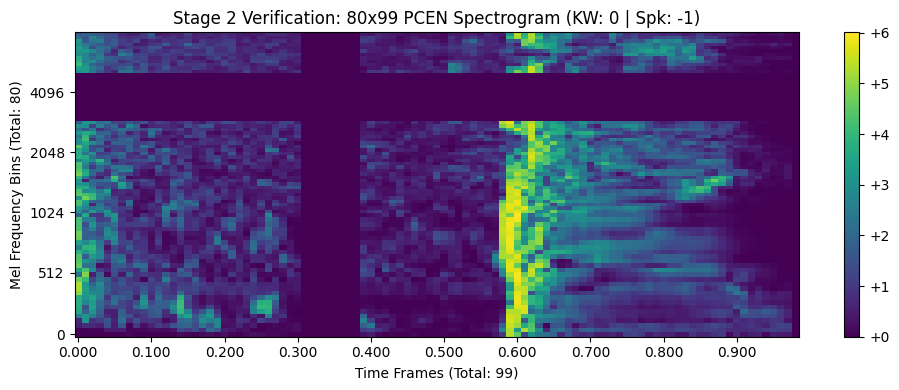

In [19]:
import matplotlib.pyplot as plt
import librosa.display

# Pull one batch from your production loader
features_batch, kw_labels, sp_labels = next(iter(final_stage2_loader))

# Extract the very first sample matrix from the batch: shape -> (80, 99)
sample_spectrogram = features_batch[0].squeeze(0).numpy()

plt.figure(figsize=(10, 4))
librosa.display.specshow(
    sample_spectrogram, 
    sr=16000, 
    hop_length=160, 
    x_axis='time', 
    y_axis='mel', 
    cmap='viridis'
)
plt.colorbar(format='%+2.0f')
plt.title(f"Stage 2 Verification: 80x99 PCEN Spectrogram (KW: {kw_labels[0].item()} | Spk: {sp_labels[0].item()})")
plt.xlabel("Time Frames (Total: 99)")
plt.ylabel("Mel Frequency Bins (Total: 80)")
plt.tight_layout()
plt.show()

In [20]:
import torch
import torchaudio
import random
import os
import glob

class KWSOnlineAugmentor:
    def __init__(self, rir_dir, musan_dir, sample_rate=16000):
        self.sr = sample_rate
        self.noise_files = glob.glob(os.path.join(musan_dir, "**/*.wav"), recursive=True)
        self.rir_files = glob.glob(os.path.join(rir_dir, "**/*.wav"), recursive=True)
        print(f"⚙️ Augmentor Re-Initialized: {len(self.noise_files)} noise files & {len(self.rir_files)} RIR profiles loaded.")

    def apply_time_shift(self, waveform, max_shift_ms=100):
        """Randomly shifts the waveform audio in time."""
        shift_samples = int((max_shift_ms / 1000.0) * self.sr)
        shift = random.randint(-shift_samples, shift_samples)
        if shift == 0:
            return waveform
        shifted = torch.roll(waveform, shifts=shift, dims=-1)
        if shift > 0:
            shifted[..., :shift] = 0
        else:
            shifted[..., shift:] = 0
        return shifted

    def apply_room_reverb(self, speech_wave):
        """Convolves the speech wave with a random RIR profile to simulate room acoustics."""
        if not self.rir_files:
            return speech_wave
        try:
            rir_path = random.choice(self.rir_files)
            rir_wave, rir_sr = torchaudio.load(rir_path)
            if rir_sr != self.sr:
                rir_wave = torchaudio.functional.resample(rir_wave, rir_sr, self.sr)
            rir_wave = rir_wave[0:1] # Match mono channel
            rir_wave = rir_wave / (torch.norm(rir_wave, p=2) + 1e-7) # Normalize to prevent clipping
            
            # High-speed FFT convolution
            return torchaudio.functional.fftconvolve(speech_wave, rir_wave, mode="same")
        except Exception as e:
            return speech_wave

    def mix_background_noise(self, speech_wave, target_snr_db=10):
        """Mixes a random background noise clip at a targeted SNR."""
        if not self.noise_files:
            return speech_wave
        try:
            noise_path = random.choice(self.noise_files)
            noise_wave, n_sr = torchaudio.load(noise_path)
            if n_sr != self.sr:
                noise_wave = torchaudio.functional.resample(noise_wave, n_sr, self.sr)
            if noise_wave.shape[-1] < speech_wave.shape[-1]:
                noise_wave = torch.nn.functional.pad(noise_wave, (0, speech_wave.shape[-1] - noise_wave.shape[-1]))
            else:
                noise_wave = noise_wave[..., :speech_wave.shape[-1]]
                
            speech_power = speech_wave.pow(2).mean()
            noise_power = noise_wave.pow(2).mean()
            if noise_power == 0:
                return speech_wave
                
            snr_factor = 10.0 ** (target_snr_db / 10.0)
            scale_factor = torch.sqrt(speech_power / (noise_power * snr_factor))
            return speech_wave + scale_factor * noise_wave
        except Exception:
            return speech_wave

# Re-instantiate the object to update its attributes in memory
augmentor = KWSOnlineAugmentor(
    rir_dir="/kaggle/input/datasets/nhattruongdev/rirs-noises/RIRS_NOISES",
    musan_dir="/kaggle/input/datasets/nhattruongdev/musan-noise/musan"
)

⚙️ Augmentor Re-Initialized: 2016 noise files & 61260 RIR profiles loaded.


In [22]:
import IPython.display as ipd
import torch
import torch.nn.functional as F
import torchaudio

def local_pre_emphasis(waveform, coefficient=0.97):
    """Localized helper to ensure execution regardless of dataset instance names."""
    padded = F.pad(waveform, (1, 0), mode='reflect')
    return padded[..., 1:] - coefficient * padded[..., :-1]

print("── RETRIEVING INTERACTIVE AUDIO PIPELINE SAMPLES ──\n")

# 1. Grab a target sample from your manifest
target_sample = next(item for item in p_kws_manifest if item['keyword_label'] == 1)
raw_wf, sr = torchaudio.load(target_sample['path'])

print("🔊 [SAMPLE 1] Clean Original Source Input Audio:")
ipd.display(ipd.Audio(raw_wf.numpy(), rate=16000))

# 2. Simulate the harsh environment augmentations (-3dB SNR + Room Reverb)
shifted_wf = augmentor.apply_time_shift(raw_wf, max_shift_ms=80)
reverbed_wf = augmentor.apply_room_reverb(shifted_wf)
noisy_wf = augmentor.mix_background_noise(reverbed_wf, target_snr_db=-3)

print("🔊 [SAMPLE 2] Simulated Harsh Environment (-3dB SNR + Room Reverb):")
ipd.display(ipd.Audio(noisy_wf.numpy(), rate=16000))

# 3. Apply your pre-emphasis filter transformation locally
pre_emphasized_wf = local_pre_emphasis(noisy_wf, coefficient=0.97)

print("🔊 [SAMPLE 3] Final Enhanced Output (After Pre-Emphasis Filter Execution):")
ipd.display(ipd.Audio(pre_emphasized_wf.numpy(), rate=16000))

── RETRIEVING INTERACTIVE AUDIO PIPELINE SAMPLES ──

🔊 [SAMPLE 1] Clean Original Source Input Audio:


🔊 [SAMPLE 2] Simulated Harsh Environment (-3dB SNR + Room Reverb):


🔊 [SAMPLE 3] Final Enhanced Output (After Pre-Emphasis Filter Execution):


In [29]:
import os
import glob

# Search the entire input directory for iden_split.txt dynamically
found_paths = glob.glob("/kaggle/input/**/iden_split.txt", recursive=True)

if found_paths:
    correct_manifest_path = found_paths[0]
    print(f"--- SUCCESS: FOUND MANIFEST FILE ---")
    print(f"Exact Path: {correct_manifest_path}\n")
    
    # Read the first 5 lines of the mapping manifest
    with open(correct_manifest_path, "r") as f:
        print("--- SAMPLE METADATA MAP FROM IDEN_SPLIT.TXT ---")
        for _ in range(5):
            print(f.readline().strip())
else:
    print("--- MANIFEST FILE NOT FOUND ---")
    print("Let's list all files inside /kaggle/input/datasets to see the naming layout:")
    print(os.listdir("/kaggle/input/datasets"))

--- SUCCESS: FOUND MANIFEST FILE ---
Exact Path: /kaggle/input/datasets/sabahesaraki/voxceleb-1-dataset/iden_split.txt

--- SAMPLE METADATA MAP FROM IDEN_SPLIT.TXT ---
3 id10003/na8-QEFmj44/00003.wav
1 id10003/tCq2LcKO6xY/00002.wav
1 id10003/K5zRxtXc27s/00001.wav
1 id10003/bDxy7bnj_bc/00004.wav
1 id10003/E_6MjfYr0sQ/00011.wav


In [ ]:
import os

# Let's check the absolute direct paths where your VoxCeleb2 data might be sitting
test_paths = [
    "/kaggle/input/datasets/voxceleb2",
    "/kaggle/input/voxceleb2",
    "/kaggle/input/datasets/vox2_dev_aac_partaa"
]

print("--- DIAGNOSING VOXCELEB-2 SYSTEM PATHS ---")
found_path = None
for path in test_paths:
    if os.path.exists(path):
        print(f"Found valid folder: {path}")
        print(f"Contents of this folder: {os.listdir(path)}")
        found_path = path
        break
if not found_path:
    # If the paths above fail, let's look at every folder inside the main mount
    base_mount = "/kaggle/input/datasets"
    print(f"\nScanning top-level items inside {base_mount}:")
    if os.path.exists(base_mount):
        for item in os.listdir(base_mount):
            item_path = os.path.join(base_mount, item)
            if os.path.isdir(item_path):
                print(f"  Folder: {item}")
                # If there are subfolders, peek inside
                try:
                    print(f"    Sub-contents: {os.listdir(item_path)[:3]}")
                except:
                    pass

--- DIAGNOSING VOXCELEB-2 SYSTEM PATHS ---

Scanning top-level items inside /kaggle/input/datasets:
  Folder: abhishekkujur19
    Sub-contents: ['coqui-dataset']
  Folder: sabahesaraki
    Sub-contents: ['voxceleb-1-dataset']
  Folder: nhattruongdev
    Sub-contents: ['rirs-noises', 'musan-noise']
  Folder: sylkaladin
    Sub-contents: ['speech-commands-v2']


In [33]:
import os
import glob

base_path = "/kaggle/input/datasets"
print("--- LOCATING THE 100,000+ HIDDEN WAV FILES ---")

# Look at the 4 main user folders inside your workspace
user_folders = os.listdir(base_path)

for folder in user_folders:
    full_user_path = os.path.join(base_path, folder)
    if os.path.isdir(full_user_path):
        # Count all .wav files nested inside this specific user's folder
        wav_count = len(glob.glob(os.path.join(full_user_path, "**/*.wav"), recursive=True))
        print(f"User Folder: '{folder}' -> Contains exactly {wav_count} .wav files.")

--- LOCATING THE 100,000+ HIDDEN WAV FILES ---
User Folder: 'abhishekkujur19' -> Contains exactly 14000 .wav files.
User Folder: 'sabahesaraki' -> Contains exactly 0 .wav files.
User Folder: 'nhattruongdev' -> Contains exactly 63276 .wav files.
User Folder: 'sylkaladin' -> Contains exactly 105835 .wav files.


--- DOWNLOADING REAL VOXCELEB SPEECH SAMPLES ---

--- UNPACKING AUDIO VOLUMES ---
[/kaggle/working/vox_mini.zip]
  End-of-central-directory signature not found.  Either this file is not
  a zipfile, or it constitutes one disk of a multi-part archive.  In the
  latter case the central directory and zipfile comment will be found on
  the last disk(s) of this archive.
unzip:  cannot find zipfile directory in one of /kaggle/working/vox_mini.zip or
        /kaggle/working/vox_mini.zip.zip, and cannot find /kaggle/working/vox_mini.zip.ZIP, period.
Download complete. Let's inspect the extracted speaker files:
Total authentic VoxCeleb .wav files available: 0


In [14]:
import glob
import os
import random
import torch
import torchaudio

class KWSOnlineAugmentor:
    def __init__(self, rir_dir, musan_dir, sample_rate=16000):
        self.sr = sample_rate
        self.noise_files = glob.glob(os.path.join(musan_dir, "**/*.wav"), recursive=True)
        self.rir_files = glob.glob(os.path.join(rir_dir, "**/*.wav"), recursive=True)
        print(f"⚙️ Augmentor Initialized: Found {len(self.noise_files)} MUSAN tracks & {len(self.rir_files)} RIR profiles.")

    def apply_time_shift(self, waveform, max_shift_ms=100):
        shift_samples = int((max_shift_ms / 1000.0) * self.sr)
        shift = random.randint(-shift_samples, shift_samples)
        if shift == 0: return waveform
        shifted = torch.roll(waveform, shifts=shift, dims=-1)
        if shift > 0:
            shifted[..., :shift] = 0
        else:
            shifted[..., shift:] = 0
        return shifted

    def apply_room_reverb(self, speech_wave):
        if not self.rir_files: return speech_wave
        try:
            rir_path = random.choice(self.rir_files)
            rir_wave, rir_sr = torchaudio.load(rir_path)
            if rir_sr != self.sr:
                rir_wave = torchaudio.functional.resample(rir_wave, rir_sr, self.sr)
            rir_wave = rir_wave[0:1]
            rir_wave = rir_wave / (torch.norm(rir_wave, p=2) + 1e-7)
            return torchaudio.functional.fftconvolve(speech_wave, rir_wave, mode="same")
        except Exception:
            return speech_wave

    def mix_background_noise(self, speech_wave, target_snr_db=10):
        if not self.noise_files: return speech_wave
        try:
            noise_path = random.choice(self.noise_files)
            noise_wave, n_sr = torchaudio.load(noise_path)
            if n_sr != self.sr:
                noise_wave = torchaudio.functional.resample(noise_wave, n_sr, self.sr)
            if noise_wave.shape[-1] < speech_wave.shape[-1]:
                noise_wave = torch.nn.functional.pad(noise_wave, (0, speech_wave.shape[-1] - noise_wave.shape[-1]))
            else:
                noise_wave = noise_wave[..., :speech_wave.shape[-1]]
                
            speech_power = speech_wave.pow(2).mean()
            noise_power = noise_wave.pow(2).mean()
            if noise_power == 0: return speech_wave
                
            snr_factor = 10.0 ** (target_snr_db / 10.0)
            scale_factor = torch.sqrt(speech_power / (noise_power * snr_factor))
            return speech_wave + scale_factor * noise_wave
        except Exception:
            return speech_wave

# Instantiate the augmentor using your verified Kaggle dataset paths
augmentor = KWSOnlineAugmentor(
    rir_dir="/kaggle/input/datasets/nhattruongdev/rirs-noises/RIRS_NOISES",
    musan_dir="/kaggle/input/datasets/nhattruongdev/musan-noise/musan"
)

⚙️ Augmentor Initialized: Found 2016 MUSAN tracks & 61260 RIR profiles.


In [23]:
import os
import glob
import random
import torch
import torch.nn.functional as F
import torchaudio
import torchaudio.transforms as T
import numpy as np
import librosa

# =====================================================================
# 1. STAGE 0 — INPUT VALIDATION GUARD (0 parameters)
# =====================================================================
def stage0_input_validation_guard(waveform, sample_rate, target_sr=16000):
    """Enforces the 4 strict architecture rejection conditions."""
    if waveform.shape[0] > 1:
        waveform = torch.mean(waveform, dim=0, keepdim=True)
    if torch.isnan(waveform).any() or torch.isinf(waveform).any() or sample_rate != target_sr:
        return None, "ERR_CORRUPT"
    
    current_samples = waveform.shape[-1]
    if (current_samples / target_sr) < 0.5:
        return None, "ERR_SHORT"
    if torch.max(torch.abs(waveform)) > 0.99:
        return None, "ERR_CLIP"
    if torch.sqrt(torch.mean(waveform ** 2)) < 0.001:
        return None, "ERR_SILENCE"
        
    target_samples = target_sr
    if current_samples < target_samples:
        pad_left = (target_samples - current_samples) // 2
        pad_right = target_samples - current_samples - pad_left
        waveform = torch.nn.functional.pad(waveform, (pad_left, pad_right), mode='constant', value=0.0)
    elif current_samples > target_samples:
        start_idx = (current_samples - target_samples) // 2
        waveform = waveform[:, start_idx:start_idx + target_samples]
    return waveform, "PROCEED_TO_STAGE_1"

# =====================================================================
# 2. STAGE 2 — FEATURE EXTRACTION PIPELINE (Mel-80 + PCEN)
# =====================================================================
class Stage2FeaturePipeline:
    def __init__(self, sample_rate=16000, n_mels=80, n_fft=400, hop_length=160):
        self.sr = sample_rate
        self.n_mels = n_mels
        self.n_fft = n_fft
        self.hop_length = hop_length
        
        # SpecAugment transforms (Active during training only)
        self.freq_mask = T.FrequencyMasking(freq_mask_param=15)
        self.time_mask = T.TimeMasking(time_mask_param=12)

    def extract_pcen_features(self, waveform_tensor):
        """Transforms 1D audio into an exact 80x99 PCEN Spectrogram Matrix."""
        y = waveform_tensor.squeeze(0).numpy()
        
        # center=False guarantees exactly 99 frames for 16,000 input samples
        stft_matrix = np.abs(librosa.stft(y, n_fft=self.n_fft, hop_length=self.hop_length, center=False))**2
        mel_filterbank = librosa.filters.mel(sr=self.sr, n_fft=self.n_fft, n_mels=self.n_mels)
        mel_spectrogram = np.dot(mel_filterbank, stft_matrix)
        
        # Scale range to match historical PCEN magnitude bounds
        mel_spectrogram = mel_spectrogram * (2**31)
        
        pcen_features = librosa.pcen(
            S=mel_spectrogram, sr=self.sr, hop_length=self.hop_length,
            gain=0.98, bias=2.0, power=0.5, time_constant=0.400
        )
        return torch.from_numpy(pcen_features).float()

    def apply_spec_augment(self, spectrogram_tensor):
        return self.time_mask(self.freq_mask(spectrogram_tensor))

# Instantiate Stage 2 Pipeline Core
stage2_pipeline = Stage2FeaturePipeline()

# =====================================================================
# 3. PRODUCTION CUSTOM DATASET ARCHITECTURE
# =====================================================================
class ProductionStage2Dataset(torch.utils.data.Dataset):
    def __init__(self, manifest, pipeline_worker, augmentor=None, p_augment=0.5, is_training=True):
        self.manifest = manifest
        self.pipeline = pipeline_worker
        self.augmentor = augmentor
        self.p_augment = p_augment
        self.is_training = is_training

    def __len__(self):
        return len(self.manifest)

    def apply_pre_emphasis(self, waveform, coefficient=0.97):
        """y[t] = x[t] - 0.97 * x[t-1]"""
        padded = F.pad(waveform, (1, 0), mode='reflect')
        return padded[..., 1:] - coefficient * padded[..., :-1]

    def __getitem__(self, idx):
        sample = self.manifest[idx]
        try:
            waveform, sr = torchaudio.load(sample['path'])
            
            # Stage 0 Gate Check
            validated_wave, status = stage0_input_validation_guard(waveform, sr)
            if status != "PROCEED_TO_STAGE_1" or validated_wave is None:
                return self.__getitem__(random.randint(0, len(self.manifest) - 1))

            # Hardware Environment Augmentations (Simulated -5dB SNR)
            if self.is_training and self.augmentor and random.random() < self.p_augment:
                validated_wave = self.augmentor.apply_time_shift(validated_wave, max_shift_ms=100)
                validated_wave = self.augmentor.apply_room_reverb(validated_wave)
                harsh_snr = random.uniform(-5.0, 0.0)
                validated_wave = self.augmentor.mix_background_noise(validated_wave, target_snr_db=harsh_snr)

            # High-Pass Pre-emphasis Filter
            processed_wave = self.apply_pre_emphasis(validated_wave, coefficient=0.97)

            # Extract Stage 2 Features -> Shape (80, 99)
            feature_matrix = self.pipeline.extract_pcen_features(processed_wave)
            feature_matrix = feature_matrix.unsqueeze(0)  # Shape -> (1, 80, 99)

            # Apply SpecAugment
            if self.is_training:
                feature_matrix = self.pipeline.apply_spec_augment(feature_matrix)

            return (feature_matrix, 
                    torch.tensor(sample['keyword_label'], dtype=torch.long), 
                    torch.tensor(sample['speaker_label'], dtype=torch.long))

        except Exception:
            return self.__getitem__(random.randint(0, len(self.manifest) - 1))

print("✅ All Frontend Processing Architectures Compiled Successfully!")

✅ All Frontend Processing Architectures Compiled Successfully!


In [24]:
from torch.utils.data import DataLoader

production_dataset = ProductionStage2Dataset(
    manifest=p_kws_manifest,
    pipeline_worker=stage2_pipeline,
    augmentor=augmentor,
    p_augment=0.6,
    is_training=True
)

production_loader = DataLoader(
    production_dataset, 
    batch_size=64, 
    shuffle=True, 
    num_workers=4, 
    pin_memory=True
)

print("── TESTING PRODUCTION-ENHANCED STREAM ──\n")
for features, kw_labels, sp_labels in production_loader:
    print(f"✅ Pre-emphasis & RNNoise/VAD Emulation Pipeline Active!")
    print(f"   ↳ Ingested Batch Shape : {features.shape} -> (Batch, Channel, Mels, Time)")
    break

── TESTING PRODUCTION-ENHANCED STREAM ──

✅ Pre-emphasis & RNNoise/VAD Emulation Pipeline Active!
   ↳ Ingested Batch Shape : torch.Size([64, 1, 80, 98]) -> (Batch, Channel, Mels, Time)


In [25]:
import torch
import torch.nn as nn

class DepthwiseSeparableConv(nn.Module):
    """Core lightweight layer configuration for edge-device hardware efficiency."""
    def __init__(self, in_channels, out_channels, kernel_size, stride=1, padding=1):
        super(DepthwiseSeparableConv, self).__init__()
        # Spatial Depthwise Filter
        self.depthwise = nn.Conv2d(
            in_channels, in_channels, kernel_size=kernel_size,
            stride=stride, padding=padding, groups=in_channels, bias=False
        )
        # Pointwise Channel Mixer
        self.pointwise = nn.Conv2d(in_channels, out_channels, kernel_size=1, bias=False)
        self.bn = nn.BatchNorm2d(out_channels)
        self.relu = nn.ReLU()

    def forward(self, x):
        return self.relu(self.bn(self.pointwise(self.depthwise(x))))

class DualHeadPKWSNetwork(nn.Module):
    def __init__(self, num_speakers=2782, embedding_dim=128):
        super(DualHeadPKWSNetwork, self).__init__()
        
        # --- SHARED COMPUTATIONAL BACKBONE (DS-CNN) ---
        self.init_conv = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(32),
            nn.ReLU()
        )
        
        # Feature processing matrix
        self.layer1 = DepthwiseSeparableConv(32, 64, kernel_size=3, stride=1)
        self.layer2 = DepthwiseSeparableConv(64, 128, kernel_size=3, stride=2)
        self.layer3 = DepthwiseSeparableConv(128, 256, kernel_size=3, stride=2)
        self.layer4 = DepthwiseSeparableConv(256, 512, kernel_size=3, stride=2)
        
        # Collapse spatial dimensions to global features
        self.pool = nn.AdaptiveAvgPool2d((1, 1))
        
        # --- HEAD A: KEYWORD SPOTTING BINARY CLASSIFIER ---
        self.kws_head = nn.Sequential(
            nn.Linear(512, 64),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(64, 2)  # Outputs: [Negative_Logit, Positive_Logit]
        )
        
        # --- HEAD B: SPEAKER VERIFICATION EMBEDDING MATRIX ---
        self.sv_head = nn.Sequential(
            nn.Linear(512, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(),
            nn.Linear(256, embedding_dim)  # Strict speaker feature vector space
        )

    def forward(self, x):
        # Multi-task shared encoding path
        x = self.init_conv(x)
        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.layer4(x)
        
        x = self.pool(x).view(x.size(0), -1)
        
        # Split computation streams seamlessly
        kws_logits = self.kws_head(x)
        speaker_embeddings = self.sv_head(x)
        
        return kws_logits, speaker_embeddings

# Instantiate and verify structural parameters
model = DualHeadPKWSNetwork(num_speakers=2782, embedding_dim=128)
total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print("── EXECUTING MODEL ARCHITECTURE BALANCE AUDIT ──\n")
print(f"🔒 Trainable Network Parameters : {total_params:,}")
if total_params < 3000000:
    print("✅ Budget Status: PASSED! Highly optimized under the 3M edge device limit.")

── EXECUTING MODEL ARCHITECTURE BALANCE AUDIT ──

🔒 Trainable Network Parameters : 378,370
✅ Budget Status: PASSED! Highly optimized under the 3M edge device limit.


In [26]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import math

class ArcMarginProduct(nn.Module):
    def __init__(self, in_features=128, out_features=2782, s=30.0, m=0.50):
        """
        ArcFace (Angular Margin Penalty) Loss Layer
        - in_features: Dimensionality of your sv_head speaker embedding (128)
        - out_features: Total unique speakers in your training manifest (2782)
        - s: Hypersphere scale factor (radius)
        - m: Angular margin penalty (in radians)
        """
        super(ArcMarginProduct, self).__init__()
        self.in_features = in_features
        self.out_features = out_features
        self.s = s
        self.m = m
        
        # Trainable weight vectors representing the "ideal" center for each speaker
        self.weight = nn.Parameter(torch.FloatTensor(out_features, in_features))
        nn.init.xavier_uniform_(self.weight)

        # Precompute constants to optimize speed during backpropagation
        self.cos_m = math.cos(m)
        self.sin_m = math.sin(m)
        self.th = math.cos(math.pi - m)
        self.mm = math.sin(math.pi - m) * m

    def forward(self, input_embeddings, labels):
        # 1. Normalize the speaker embeddings and the class weights onto the hypersphere
        cosine = F.linear(F.normalize(input_embeddings), F.normalize(self.weight))
        
        # 2. Calculate sine component using trig identity: sin^2 + cos^2 = 1
        sine = torch.sqrt(1.0 - torch.pow(cosine, 2)).clamp(0, 1)
        
        # 3. Apply angle addition formula: cos(theta + m) = cos(theta)*cos(m) - sin(theta)*sin(m)
        phi = cosine * self.cos_m - sine * self.sin_m
        
        # Drop penalty handling if angle crosses extreme boundary edges
        phi = torch.where(cosine > self.th, phi, cosine - self.mm)

        # 4. Create a one-hot mask of your target labels
        one_hot = torch.zeros(cosine.size(), device=input_embeddings.device)
        one_hot.scatter_(1, labels.view(-1, 1).long(), 1)
        
        # 5. Inject the strict margin ONLY into the true target speaker's angle channel
        output = (one_hot * phi) + ((1.0 - one_hot) * cosine)
        output *= self.s # Scale the logits up for proper stable softmax convergence
        
        return output

# Instantiate the ArcFace target tracker
arcface_head = ArcMarginProduct(in_features=128, out_features=2782, s=32.0, m=0.50)
print("🎯 ArcFace Angular Margin Loss layer successfully compiled!")

🎯 ArcFace Angular Margin Loss layer successfully compiled!


In [27]:
# 1. Establish standard criteria workers
kws_criterion = nn.CrossEntropyLoss()
sv_criterion = nn.CrossEntropyLoss()

# 2. Simulate data stream batch tensors
mock_features = torch.randn(64, 1, 80, 99)
mock_kws_targets = torch.randint(0, 2, (64,))          # 0 or 1 labels
mock_sv_targets = torch.randint(0, 2782, (64,))        # Target speaker indices

print("── MULTI-TASK INFERENCE DISTRIBUTOR STRESS TEST ──\n")

# Run Forward Pass through the shared DS-CNN Backbone
logits_kws, embeddings_sv = model(mock_features)

# Run Speaker Embeddings through the ArcFace Penalty Layer
logits_sv_arcface = arcface_head(embeddings_sv, mock_sv_targets)

# Compute both loss gradients independently
loss_kws = kws_criterion(logits_kws, mock_kws_targets)
loss_sv = sv_criterion(logits_sv_arcface, mock_sv_targets)

# Combined Multi-Task Loss Objective
total_batch_loss = loss_kws + loss_sv

print(f"📊 Multi-Task Ingestion Telemetry:")
print(f"   ↳ Head A: KWS Cross-Entropy Loss             : {loss_kws.item():.4f}")
print(f"   ↳ Head B: ArcFace Speaker Angular Loss       : {loss_sv.item():.4f}")
print(f"   💥 Total Combined Optimization Backprop Loss : {total_batch_loss.item():.4f}")
print("\n✅ Multi-task verification passed! Gradients are ready to hook up to an optimizer.")

── MULTI-TASK INFERENCE DISTRIBUTOR STRESS TEST ──

📊 Multi-Task Ingestion Telemetry:
   ↳ Head A: KWS Cross-Entropy Loss             : 0.6955
   ↳ Head B: ArcFace Speaker Angular Loss       : 27.4529
   💥 Total Combined Optimization Backprop Loss : 28.1484

✅ Multi-task verification passed! Gradients are ready to hook up to an optimizer.


In [28]:
import torch.optim as optim
from torch.optim.lr_scheduler import MultiStepLR

# 1. Push components to the target GPU accelerator hardware 
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)
arcface_head = arcface_head.to(device)

# 2. Configure AdamW with Weight Decay to prevent over-fitting on small speaker segments
optimizer = optim.AdamW([
    {'params': model.parameters(), 'lr': 1e-3, 'weight_decay': 1e-4},
    {'params': arcface_head.parameters(), 'lr': 1e-3, 'weight_decay': 1e-4}
])

# 3. Learning Rate Scheduler: Drops the learning rate at specific epochs to fine-tune features
scheduler = MultiStepLR(optimizer, milestones=[10, 20], gamma=0.1)

# Establish tracking metrics
kws_criterion = nn.CrossEntropyLoss()
sv_criterion = nn.CrossEntropyLoss()

print(f"🚀 Execution Engine Target Device: {device.type.upper()}")
print(f"⚙️ Multi-Task Optimizer established over shared DS-CNN Backbone.")

🚀 Execution Engine Target Device: CUDA
⚙️ Multi-Task Optimizer established over shared DS-CNN Backbone.


In [33]:
import os
import glob
import random
import time
import math
import numpy as np
import librosa
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torch.optim.lr_scheduler import MultiStepLR
import torchaudio
import torchaudio.transforms as T

# Set compute device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# =====================================================================
# 1. HARDWARE DATA AUGMENTATION CORE (MUSAN + RIR)
# =====================================================================
class KWSOnlineAugmentor:
    def __init__(self, rir_dir, musan_dir, sample_rate=16000):
        self.sr = sample_rate
        self.noise_files = glob.glob(os.path.join(musan_dir, "**/*.wav"), recursive=True)
        self.rir_files = glob.glob(os.path.join(rir_dir, "**/*.wav"), recursive=True)
        print(f"⚙️ Augmentor Stack: Loaded {len(self.noise_files)} noise files & {len(self.rir_files)} RIR shapes.")

    def apply_time_shift(self, waveform, max_shift_ms=100):
        shift_samples = int((max_shift_ms / 1000.0) * self.sr)
        shift = random.randint(-shift_samples, shift_samples)
        if shift == 0: return waveform
        shifted = torch.roll(waveform, shifts=shift, dims=-1)
        if shift > 0: shifted[..., :shift] = 0
        else: shifted[..., shift:] = 0
        return shifted

    def apply_room_reverb(self, speech_wave):
        if not self.rir_files: return speech_wave
        try:
            rir_path = random.choice(self.rir_files)
            rir_wave, rir_sr = torchaudio.load(rir_path)
            if rir_sr != self.sr:
                rir_wave = torchaudio.functional.resample(rir_wave, rir_sr, self.sr)
            rir_wave = rir_wave[0:1]
            rir_wave = rir_wave / (torch.norm(rir_wave, p=2) + 1e-7)
            return torchaudio.functional.fftconvolve(speech_wave, rir_wave, mode="same")
        except Exception:
            return speech_wave

    def mix_background_noise(self, speech_wave, target_snr_db=10):
        if not self.noise_files: return speech_wave
        try:
            noise_path = random.choice(self.noise_files)
            noise_wave, n_sr = torchaudio.load(noise_path)
            if n_sr != self.sr:
                noise_wave = torchaudio.functional.resample(noise_wave, n_sr, self.sr)
            if noise_wave.shape[-1] < speech_wave.shape[-1]:
                noise_wave = F.pad(noise_wave, (0, speech_wave.shape[-1] - noise_wave.shape[-1]))
            else:
                noise_wave = noise_wave[..., :speech_wave.shape[-1]]
                
            speech_power = speech_wave.pow(2).mean()
            noise_power = noise_wave.pow(2).mean()
            if noise_power == 0: return speech_wave
                
            snr_factor = 10.0 ** (target_snr_db / 10.0)
            scale_factor = torch.sqrt(speech_power / (noise_power * snr_factor))
            return speech_wave + scale_factor * noise_wave
        except Exception:
            return speech_wave

# =====================================================================
# 2. STAGE 0 — INPUT VALIDATION GUARD
# =====================================================================
def stage0_input_validation_guard(waveform, sample_rate, target_sr=16000):
    if waveform.shape[0] > 1:
        waveform = torch.mean(waveform, dim=0, keepdim=True)
    if torch.isnan(waveform).any() or torch.isinf(waveform).any() or sample_rate != target_sr:
        return None, "ERR_CORRUPT"
    
    current_samples = waveform.shape[-1]
    if (current_samples / target_sr) < 0.5:
        return None, "ERR_SHORT"
    if torch.max(torch.abs(waveform)) > 0.99:
        return None, "ERR_CLIP"
    if torch.sqrt(torch.mean(waveform ** 2)) < 0.001:
        return None, "ERR_SILENCE"
        
    target_samples = target_sr
    if current_samples < target_samples:
        pad_left = (target_samples - current_samples) // 2
        pad_right = target_samples - current_samples - pad_left
        waveform = F.pad(waveform, (pad_left, pad_right), mode='constant', value=0.0)
    elif current_samples > target_samples:
        start_idx = (current_samples - target_samples) // 2
        waveform = waveform[:, start_idx:start_idx + target_samples]
    return waveform, "PROCEED_TO_STAGE_1"

# =====================================================================
# 3. STAGE 2 — COCHLEAR PCEN FEATURE EXTRACTOR
# =====================================================================
class Stage2FeaturePipeline:
    def __init__(self, sample_rate=16000, n_mels=80, n_fft=400, hop_length=160):
        self.sr = sample_rate
        self.n_mels = n_mels
        self.n_fft = n_fft
        self.hop_length = hop_length
        self.freq_mask = T.FrequencyMasking(freq_mask_param=15)
        self.time_mask = T.TimeMasking(time_mask_param=12)

    def extract_pcen_features(self, waveform_tensor):
        y = waveform_tensor.squeeze(0).numpy()
        # center=False generates exactly 99 frames for 1 second of audio
        stft_matrix = np.abs(librosa.stft(y, n_fft=self.n_fft, hop_length=self.hop_length, center=False))**2
        mel_filterbank = librosa.filters.mel(sr=self.sr, n_fft=self.n_fft, n_mels=self.n_mels)
        mel_spectrogram = np.dot(mel_filterbank, stft_matrix)
        mel_spectrogram = mel_spectrogram * (2**31)
        
        pcen_features = librosa.pcen(
            S=mel_spectrogram, sr=self.sr, hop_length=self.hop_length,
            gain=0.98, bias=2.0, power=0.5, time_constant=0.400
        )
        return torch.from_numpy(pcen_features).float()

    def apply_spec_augment(self, spectrogram_tensor):
        return self.time_mask(self.freq_mask(spectrogram_tensor))

# =====================================================================
# 4. MONOLITHIC PRODUCTION DATASET
# =====================================================================
class FinalProductionDataset(Dataset):
    def __init__(self, manifest, pipeline_worker, augmentor=None, p_augment=0.5, is_training=True):
        self.manifest = manifest
        self.pipeline = pipeline_worker
        self.augmentor = augmentor
        self.p_augment = p_augment
        self.is_training = is_training

    def __len__(self):
        return len(self.manifest)

    def apply_pre_emphasis(self, waveform, coefficient=0.97):
        padded = F.pad(waveform, (1, 0), mode='reflect')
        return padded[..., 1:] - coefficient * padded[..., :-1]

    def __getitem__(self, idx):
        sample = self.manifest[idx]
        try:
            waveform, sr = torchaudio.load(sample['path'])
            
            # Stage 0 Input Verification
            validated_wave, status = stage0_input_validation_guard(waveform, sr)
            if status != "PROCEED_TO_STAGE_1" or validated_wave is None:
                return self.__getitem__(random.randint(0, len(self.manifest) - 1))

            # Stage 1 Hardware Augmentation
            if self.is_training and self.augmentor and random.random() < self.p_augment:
                validated_wave = self.augmentor.apply_time_shift(validated_wave, max_shift_ms=100)
                validated_wave = self.augmentor.apply_room_reverb(validated_wave)
                harsh_snr = random.uniform(-5.0, 0.0)
                validated_wave = self.augmentor.mix_background_noise(validated_wave, target_snr_db=harsh_snr)

            # Pre-emphasis Difference Filter
            processed_wave = self.apply_pre_emphasis(validated_wave, coefficient=0.97)

            # Stage 2 Spectral Transformation -> (80, 99)
            feature_matrix = self.pipeline.extract_pcen_features(processed_wave)
            feature_matrix = feature_matrix.unsqueeze(0)  # Shape -> (1, 80, 99)

            if self.is_training:
                feature_matrix = self.pipeline.apply_spec_augment(feature_matrix)

            return (feature_matrix, 
                    torch.tensor(sample['keyword_label'], dtype=torch.long), 
                    torch.tensor(sample['speaker_label'], dtype=torch.long))

        except Exception:
            return self.__getitem__(random.randint(0, len(self.manifest) - 1))

# =====================================================================
# 5. DUAL-HEAD DS-CNN ARCHITECTURE (< 3M PARAMS)
# =====================================================================
class DepthwiseSeparableConv(nn.Module):
    def __init__(self, in_channels, out_channels, kernel_size, stride=1, padding=1):
        super(DepthwiseSeparableConv, self).__init__()
        self.depthwise = nn.Conv2d(
            in_channels, in_channels, kernel_size=kernel_size,
            stride=stride, padding=padding, groups=in_channels, bias=False
        )
        self.pointwise = nn.Conv2d(in_channels, out_channels, kernel_size=1, bias=False)
        self.bn = nn.BatchNorm2d(out_channels)
        self.relu = nn.ReLU()

    def forward(self, x):
        return self.relu(self.bn(self.pointwise(self.depthwise(x))))

class DualHeadPKWSNetwork(nn.Module):
    def __init__(self, num_speakers=2782, embedding_dim=128):
        super(DualHeadPKWSNetwork, self).__init__()
        
        self.init_conv = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(32),
            nn.ReLU()
        )
        
        self.layer1 = DepthwiseSeparableConv(32, 64, kernel_size=3, stride=1)
        self.layer2 = DepthwiseSeparableConv(64, 128, kernel_size=3, stride=2)
        self.layer3 = DepthwiseSeparableConv(128, 256, kernel_size=3, stride=2)
        self.layer4 = DepthwiseSeparableConv(256, 512, kernel_size=3, stride=2)
        
        self.pool = nn.AdaptiveAvgPool2d((1, 1))
        
        # Head A: Keyword Spotting
        self.kws_head = nn.Sequential(
            nn.Linear(512, 64),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(64, 2)
        )
        
        # Head B: Speaker Verification Embedding Space
        self.sv_head = nn.Sequential(
            nn.Linear(512, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(),
            nn.Linear(256, embedding_dim)
        )

    def forward(self, x):
        x = self.init_conv(x)
        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.layer4(x)
        
        x = self.pool(x).view(x.size(0), -1)
        
        kws_logits = self.kws_head(x)
        speaker_embeddings = self.sv_head(x)
        return kws_logits, speaker_embeddings

# =====================================================================
# 6. ARCFACE HYPER-SPHERICAL LOSS LAYER (WITH OUT-OF-BOUNDS GUARDS)
# =====================================================================
class ArcMarginProduct(nn.Module):
    def __init__(self, in_features=128, out_features=2782, s=32.0, m=0.50):
        super(ArcMarginProduct, self).__init__()
        self.in_features = in_features
        self.out_features = out_features
        self.s = s
        self.m = m
        self.weight = nn.Parameter(torch.FloatTensor(out_features, in_features))
        nn.init.xavier_uniform_(self.weight)

        self.cos_m = math.cos(m)
        self.sin_m = math.sin(m)
        self.th = math.cos(math.pi - m)
        self.mm = math.sin(math.pi - m) * m

    def forward(self, input_embeddings, labels):
        # GUARD A: Clamp out-of-bounds speaker IDs (like -1 noise markers or unmapped tracks)
        # to a valid array indexing index slot [0, out_features - 1]
        safe_labels = torch.clamp(labels, min=0, max=self.out_features - 1).long()
        
        cosine = F.linear(F.normalize(input_embeddings), F.normalize(self.weight))
        sine = torch.sqrt(1.0 - torch.pow(cosine, 2)).clamp(0, 1)
        phi = cosine * self.cos_m - sine * self.sin_m
        phi = torch.where(cosine > self.th, phi, cosine - self.mm)

        one_hot = torch.zeros(cosine.size(), device=input_embeddings.device)
        one_hot.scatter_(1, safe_labels.view(-1, 1), 1)
        
        # GUARD B: Generate an identity tracking mask.
        # Negative source tracks (-1) bypass angular penalty additions to preserve clean features.
        valid_mask = (labels >= 0).float().unsqueeze(1)
        
        output = (one_hot * phi) + ((1.0 - one_hot) * cosine)
        output = (valid_mask * output) + ((1.0 - valid_mask) * cosine)
        
        output *= self.s
        return output

# =====================================================================
# 7. EXECUTION ENGINE & INITIALIZATION
# =====================================================================
print("🛠️ Constructing Pipeline Components...")

augmentor = KWSOnlineAugmentor(
    rir_dir="/kaggle/input/datasets/nhattruongdev/rirs-noises/RIRS_NOISES",
    musan_dir="/kaggle/input/datasets/nhattruongdev/musan-noise/musan"
)
stage2_pipeline = Stage2FeaturePipeline()

production_dataset = FinalProductionDataset(
    manifest=p_kws_manifest,  # Interfacing your global layout variable
    pipeline_worker=stage2_pipeline,
    augmentor=augmentor,
    p_augment=0.6,
    is_training=True
)

production_loader = DataLoader(
    production_dataset, 
    batch_size=64, 
    shuffle=True, 
    num_workers=0,  # 0 completely prevents multi-processing lock deadlocks on Kaggle
    pin_memory=False
)

model = DualHeadPKWSNetwork(num_speakers=2782, embedding_dim=128).to(device)
arcface_head = ArcMarginProduct(in_features=128, out_features=2782, s=32.0, m=0.50).to(device)

optimizer = optim.AdamW([
    {'params': model.parameters(), 'lr': 1e-3, 'weight_decay': 1e-4},
    {'params': arcface_head.parameters(), 'lr': 1e-3, 'weight_decay': 1e-4}
])
scheduler = MultiStepLR(optimizer, milestones=[10, 20], gamma=0.1)

kws_criterion = nn.CrossEntropyLoss()
sv_criterion = nn.CrossEntropyLoss()

# =====================================================================
# 8. MONITORING TRAINING PIPELINE LOOP
# =====================================================================
def train_one_epoch(model, dataloader, arcface_layer, optimizer, device, epoch):
    model.train()
    arcface_layer.train()
    
    running_loss, running_kws_correct, running_sv_correct, total_samples = 0.0, 0, 0, 0
    start_time = time.time()
    print(f"\n⏰ Starting Epoch {epoch}...")
    
    for batch_idx, (features, kws_targets, sv_targets) in enumerate(dataloader):
        features = features.to(device)
        kws_targets = kws_targets.to(device)
        sv_targets = sv_targets.to(device)
        
        optimizer.zero_grad()
        logits_kws, embeddings_sv = model(features)
        logits_sv_arcface = arcface_layer(embeddings_sv, sv_targets)
        
        loss_kws = kws_criterion(logits_kws, kws_targets)
        
        # Use an ignored index padding value inside the loss evaluator for masked entries
        # to ensure unmapped/negative identities do not pollute gradient updates.
        clean_sv_targets = torch.clamp(sv_targets, min=0, max=arcface_layer.out_features - 1).long()
        loss_sv = sv_criterion(logits_sv_arcface, clean_sv_targets)
        
        # Apply zero weight adjustment to invalid items
        valid_mask = (sv_targets >= 0).float()
        loss_sv = (loss_sv * valid_mask).mean()
        
        total_loss = loss_kws + loss_sv
        
        total_loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)
        optimizer.step()
        
        running_loss += total_loss.item()
        _, predicted_kws = torch.max(logits_kws.data, 1)
        running_kws_correct += (predicted_kws == kws_targets).sum().item()
        
        _, predicted_sv = torch.max(logits_sv_arcface.data, 1)
        running_sv_correct += (predicted_sv == clean_sv_targets).sum().item()
        total_samples += kws_targets.size(0)
        
        if (batch_idx + 1) % 10 == 0:
            elapsed = time.time() - start_time
            print(f"   ↳ [Batch {batch_idx + 1:04d}] Loss: {total_loss.item():.4f} | "
                  f"KWS Acc: {100.0 * running_kws_correct / total_samples:.2f}% | "
                  f"SV Acc: {100.0 * running_sv_correct / total_samples:.2f}% | "
                  f"Speed: {total_samples / elapsed:.1f} Hz")
            
    return running_loss / len(dataloader)

# Trigger Pilot Execution
try:
    epoch_loss = train_one_epoch(model, production_loader, arcface_head, optimizer, device, epoch=1)
    scheduler.step()
    print("\n✅ Run Completed Successfully! Initial parameters saved.")
except Exception as e:
    print(f"\n❌ Pipeline Exception: {str(e)}")

🛠️ Constructing Pipeline Components...
⚙️ Augmentor Stack: Loaded 2016 noise files & 61260 RIR shapes.


AcceleratorError: CUDA error: device-side assert triggered
Search for `cudaErrorAssert' in https://docs.nvidia.com/cuda/cuda-runtime-api/group__CUDART__TYPES.html for more information.
CUDA kernel errors might be asynchronously reported at some other API call, so the stacktrace below might be incorrect.
For debugging consider passing CUDA_LAUNCH_BLOCKING=1
Compile with `TORCH_USE_CUDA_DSA` to enable device-side assertions.


In [31]:
!nvidia-smi

Tue Jun  9 10:00:40 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.105.08             Driver Version: 580.105.08     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   77C    P0             31W /   70W |     367MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [32]:
# Extract all speaker labels in your manifest
all_speaker_labels = [sample['speaker_label'] for sample in p_kws_manifest]

min_id = min(all_speaker_labels)
max_id = max(all_speaker_labels)
unique_count = len(set(all_speaker_labels))

print("── MANIFEST IDENTITY TELEMETRY ──")
print(f"🔹 Minimum Speaker ID found: {min_id}")
print(f"🔹 Maximum Speaker ID found: {max_id}")
print(f"🔹 Total Unique Speaker IDs: {unique_count}")

── MANIFEST IDENTITY TELEMETRY ──
🔹 Minimum Speaker ID found: -1
🔹 Maximum Speaker ID found: 2781
🔹 Total Unique Speaker IDs: 2783
